# Convert Exodus mesh to PFLOTRAN mesh

This workflow shows the processes of converting Exodus meshes (generated by Watershed-Workflow or Tinerator) to meshes that can be read by PFLOTRAN. 

Prerequisite:
- convert the raw Exodus meshes to *simplex* meshes (meshes that can be visualized by ParaView that reordered the mesh grids from "arbitrarily unstructured" mesh to "simplex unstructured" mesh) using the `meshconvert` command. `meshconvert` is installed as part of ATS installation and can be found in the same folder where ats executable sits.

```bash
meshconvert mesh.exo mesh-simplex.exo
```

Required source codes:
- `ncdump.py`. This script can be downloaded from [Chris Slocum's website](http://schubert.atmos.colostate.edu/~cslocum/netcdf_example.html#code)
- `exodus2pflotran.py`. This script is modified from the Python2 version on [PFLOTRAN Bitbucket](https://bitbucket.org/pflotran/pflotran/src/master/src/python/exodus2pflotran/exodus2pflotran.py) and a few bugs were fixed. Will push this version to the repo in the future.

Contact: Chao Zeng, chao.zeng@pnnl.gov

In [1]:
from netCDF4 import Dataset 
# from ncdump import ncdump
# import datetime as dt
import matplotlib.pyplot as plt
from matplotlib import cm
# from mpl_toolkits.basemap import Basemap, addcyclic, shiftgrid
from mpl_toolkits.mplot3d import Axes3D

import h5py as h5
import os
import numpy as np
import pandas as pd
import pickle

# from exodus2pflotran import exodus_to_pflotran_mesh
path=os.getcwd()
print(path)
import sys
sys.path.append('/global/u1/z/zc727/.conda/envs')
sys.path.append('/global/homes/z/zc727/.local/perlmutter/python-3.11/lib/python3.11/site-packages')
print(sys.path)
print(sys.version)
print(sys.executable)

import rasterio
# import tqdm
from tqdm.notebook import tqdm
import seaborn as sns

from shapely.geometry.polygon import Polygon
from shapely.geometry import Point
import shapefile

# from fav_colors import fav_colors
# from myfunc import print_structure, closest_node

%matplotlib inline
import matplotlib as mpl
mpl.rcParams['figure.dpi'] = 150

/global/u1/z/zc727/HFR/notebooks
['/global/u1/z/zc727/HFR/notebooks', '/opt/nersc/pymon', '/global/common/software/nersc/pe/conda-envs/24.1.0/python-3.11/nersc-python/lib/python311.zip', '/global/common/software/nersc/pe/conda-envs/24.1.0/python-3.11/nersc-python/lib/python3.11', '/global/common/software/nersc/pe/conda-envs/24.1.0/python-3.11/nersc-python/lib/python3.11/lib-dynload', '', '/global/homes/z/zc727/.local/perlmutter/python-3.11/lib/python3.11/site-packages', '/global/common/software/nersc/pe/conda-envs/24.1.0/python-3.11/nersc-python/lib/python3.11/site-packages', '/global/u1/z/zc727/.conda/envs', '/global/homes/z/zc727/.local/perlmutter/python-3.11/lib/python3.11/site-packages']
3.11.7 | packaged by conda-forge | (main, Dec 23 2023, 14:43:09) [GCC 12.3.0]
/global/common/software/nersc/pe/conda-envs/24.1.0/python-3.11/nersc-python/bin/python


In [2]:
os.environ["current_DIR"] = "$HOME/HFR/notebooks"
import sys
sys.path.append(os.environ["current_DIR"])

from myfunc import print_structure, closest_node
from exodus2pflotran import exodus_to_pflotran_mesh
from ncdump import ncdump
from fav_colors import fav_colors
#from myfunctions.exodus2pflotran import exodus_to_pflotran_mesh, print_structure, closest_node
#from myfunctions.ncdump import ncdump
#from myfunctions.colors import colors

In [3]:
os.chdir('../mesh/')
print("Current Working Directory " , os.getcwd())

Current Working Directory  /global/u1/z/zc727/HFR/mesh


In [4]:
# fname_raw_exo = 'hanford_mesh_coarse.exo'
name = "hanford_100m-updated"
mesh_dir = "/global/cfs/cdirs/m1800/pin/github/HFR-thorne/data/mesh/"
# fname_exo_mesh = 'hanford-mesh-10m-20pct-simplex.exo'
fname_exo_mesh = 'hanford_100m-updated-simplex.exo'
fname_pfotran_mesh = '{}-cvrt.h5'.format(name)
fname_out_h5 = '{}-layerID.h5'.format(name)
fname_mesh_matID = '{}-matID.h5'.format(name)
fname_mesh_matID_river = '{}-matID-river.h5'.format(name)

bigdata_dir = '/global/cfs/cdirs/m1800/pin/github/HFR-thorne/big_data/'
fname_dem = bigdata_dir + 'DEM/topobathymetry_20200312_10m.tif'
# fname_dem = data_dir + 'DEM/DEM_thorne_v2.tif'
fname_hanford_basal = bigdata_dir + 'DEM/hanford_basal.asc'
fname_ringolde_basal = bigdata_dir + 'DEM/ringolde_basal.asc'
fname_basalt_basal = bigdata_dir + 'DEM/basalt_basal.asc'
fname_ringoldlm_basal = bigdata_dir + 'DEM/ringoldlm_basal.asc'
fname_ringolda_basal = bigdata_dir + 'DEM/ringolda_basal.asc'
fname_coldcreek_basal = bigdata_dir + 'DEM/coldcreek_basal.asc'
fname_taylorflats_basal = bigdata_dir + 'DEM/taylorflats_basal.asc'

data_dir = '/global/cfs/cdirs/m1800/pin/github/HFR-thorne/data/'
fname_river_shp = data_dir + 'shapefile/river_geometry_watershed.shp'
fname_mass1_coord = data_dir + "mass1/Mass1_datum_shift.csv"

## view exodus file

In [5]:
filepath = mesh_dir+fname_exo_mesh
exofile=Dataset(filepath)

ncdump(exofile)

NetCDF Global Attributes:
	api_version: 7.03
	version: 7.03
	floating_point_word_size: 8
	file_size: 1
	maximum_name_length: 32
	int64_status: 0
	title: 'hanford_100m-updated-simplex.exo'
NetCDF dimension information:
	Name: len_string
		size: 33
	Name: len_line
		size: 81
	Name: four
		size: 4
	Name: len_name
		size: 256
	Name: time_step
		size: 0
	Name: num_dim
		size: 3
	Name: num_nodes
		size: 482336
	Name: num_elem
		size: 902937
	Name: num_el_blk
		size: 31
	Name: num_side_sets
		size: 3
	Name: num_el_in_blk1
		size: 29127
	Name: num_nod_per_el1
		size: 6
	Name: num_att_in_blk1
		size: 1
	Name: num_el_in_blk2
		size: 29127
	Name: num_nod_per_el2
		size: 6
	Name: num_att_in_blk2
		size: 1
	Name: num_el_in_blk3
		size: 29127
	Name: num_nod_per_el3
		size: 6
	Name: num_att_in_blk3
		size: 1
	Name: num_el_in_blk4
		size: 29127
	Name: num_nod_per_el4
		size: 6
	Name: num_att_in_blk4
		size: 1
	Name: num_el_in_blk5
		size: 29127
	Name: num_nod_per_el5
		size: 6
	Name: num_att_in_blk5
	

(['api_version',
  'version',
  'floating_point_word_size',
  'file_size',
  'maximum_name_length',
  'int64_status',
  'title'],
 ['len_string',
  'len_line',
  'four',
  'len_name',
  'time_step',
  'num_dim',
  'num_nodes',
  'num_elem',
  'num_el_blk',
  'num_side_sets',
  'num_el_in_blk1',
  'num_nod_per_el1',
  'num_att_in_blk1',
  'num_el_in_blk2',
  'num_nod_per_el2',
  'num_att_in_blk2',
  'num_el_in_blk3',
  'num_nod_per_el3',
  'num_att_in_blk3',
  'num_el_in_blk4',
  'num_nod_per_el4',
  'num_att_in_blk4',
  'num_el_in_blk5',
  'num_nod_per_el5',
  'num_att_in_blk5',
  'num_el_in_blk6',
  'num_nod_per_el6',
  'num_att_in_blk6',
  'num_el_in_blk7',
  'num_nod_per_el7',
  'num_att_in_blk7',
  'num_el_in_blk8',
  'num_nod_per_el8',
  'num_att_in_blk8',
  'num_el_in_blk9',
  'num_nod_per_el9',
  'num_att_in_blk9',
  'num_el_in_blk10',
  'num_nod_per_el10',
  'num_att_in_blk10',
  'num_el_in_blk11',
  'num_nod_per_el11',
  'num_att_in_blk11',
  'num_el_in_blk12',
  'num_nod_per_

## Convert Exodus file to PFLOTRAN mesh

In [6]:
filepath2 = '/global/homes/z/zc727/HFR/mesh/'+fname_pfotran_mesh
exodus_to_pflotran_mesh(filepath, filepath2)

Infile: /global/cfs/cdirs/m1800/pin/github/HFR-thorne/data/mesh/hanford_100m-updated-simplex.exo Outfile: /global/homes/z/zc727/HFR/mesh/hanford_100m-updated-cvrt.h5
Preparing Domain/Vertices
Preparing Domain/Cells
Working on block 1
Block 1: num_of_ele = 29127, num_nod_per_ele = 6
Working on block 2
Block 2: num_of_ele = 29127, num_nod_per_ele = 6
Working on block 3
Block 3: num_of_ele = 29127, num_nod_per_ele = 6
Working on block 4
Block 4: num_of_ele = 29127, num_nod_per_ele = 6
Working on block 5
Block 5: num_of_ele = 29127, num_nod_per_ele = 6
Working on block 6
Block 6: num_of_ele = 29127, num_nod_per_ele = 6
Working on block 7
Block 7: num_of_ele = 29127, num_nod_per_ele = 6
Working on block 8
Block 8: num_of_ele = 29127, num_nod_per_ele = 6
Working on block 9
Block 9: num_of_ele = 29127, num_nod_per_ele = 6
Working on block 10
Block 10: num_of_ele = 29127, num_nod_per_ele = 6
Working on block 11
Block 11: num_of_ele = 29127, num_nod_per_ele = 6
Working on block 12
Block 12: num

## Rewrite hdf5 file structure

### Duplicate hdf5 file

In [7]:
input_h5 = h5.File(filepath2, "r")

input_h5.visititems(print_structure)

Domain
Domain/Cells
Domain/Vertices
Materials
Materials/Cell Ids
Materials/Material Ids
Regions
Regions/Sideset1
Regions/Sideset2
Regions/Sideset3


In [8]:
if os.path.exists(fname_out_h5):
    os.remove(fname_out_h5)
output_h5 = h5.File(fname_out_h5, "w")

In [9]:
groups = list(input_h5.keys())
for i_group in groups:
    print(i_group)
    group_id = output_h5.require_group(i_group)
    datasets = list(input_h5[i_group].keys())
    for i_dataset in datasets:
        print(i_dataset)
        input_h5.copy("/" + i_group + "/" + i_dataset,
                      group_id, name=i_dataset)

Domain
Cells
Vertices
Materials
Cell Ids
Material Ids
Regions
Sideset1
Sideset2
Sideset3


### write datasets

For meshes generated by Watershed-workflow:

- default sidesets name: 1: 'Bottom', 2: 'Top' , 3: 'Sides', (NLCD facesets, etc.)

For meshes generated by Tinerator:

- for basic sidesets: 1. Top, 2. Bottom , 3. Sides
- for custom facesets: 1. Side land; 2. Side river; 3. Top river; 4. Top land; 5. Top; 6. Bottom; 7. Sides

**Note**: 

- sidesets names can be found from the raw "arbitrarily unstructured" mesh, but not from the simplex mesh?
- no space is allowed in group name in HDF5

In [10]:
dset_Cells = input_h5['Materials/Cell Ids']
dset_IDs = input_h5['Materials/Material Ids']

In [166]:
print(np.unique(dset_IDs))

[ 1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23 24
 25 26 27 28 29 30 31]


In [11]:
output_h5.create_group("Regions/All")
output_h5.create_dataset("Regions/All/Cell Ids", data=dset_Cells)

<HDF5 dataset "Cell Ids": shape (902937,), type "<i8">

**Rename sidesets**

**note: no space is allowed in group name in HDF5**

In [12]:
# sidesets_name = {1: 'Top', 2: 'Bottom' , 3: 'Sides'} # the default sequence in exodus file for mesh exported from tinerator
sidesets_name = {1: 'Bottom', 2: 'Top' , 3: 'Sides'} # the default for mesh exported from watershed_workflow
# sidesets_name = {1: 'Side_land', 2: 'Side_river', 3: 'Top_river', 4: 'Top_land', 5: 'Top', 6: 'Bottom' , 7: 'Sides'}

In [13]:
for key, value in sidesets_name.items():
    dset_ss = input_h5['Regions/Sideset' + str(key)]
    
    output_h5.create_group("Regions/{}".format(value))
    output_h5.create_dataset("Regions/{}/Vertex Ids".format(value), data=dset_ss)
    
    del output_h5['Regions/Sideset' + str(key)]

**create `Layer Ids` dataset**

In [14]:
output_h5.create_dataset("Materials/Layer Ids", data=dset_IDs)

<HDF5 dataset "Layer Ids": shape (902937,), type "<i8">

In [15]:
output_h5.visititems(print_structure)

Domain
Domain/Cells
Domain/Vertices
Materials
Materials/Cell Ids
Materials/Layer Ids
Materials/Material Ids
Regions
Regions/All
Regions/All/Cell Ids
Regions/Bottom
Regions/Bottom/Vertex Ids
Regions/Sides
Regions/Sides/Vertex Ids
Regions/Top
Regions/Top/Vertex Ids


In [16]:
input_h5.close()
output_h5.close()

# Generate material ids

## get vertices, cell ids, and layer ids

In [17]:
input_h5 = h5.File(fname_out_h5, "r")

input_h5.visititems(print_structure)

Domain
Domain/Cells
Domain/Vertices
Materials
Materials/Cell Ids
Materials/Layer Ids
Materials/Material Ids
Regions
Regions/All
Regions/All/Cell Ids
Regions/Bottom
Regions/Bottom/Vertex Ids
Regions/Sides
Regions/Sides/Vertex Ids
Regions/Top
Regions/Top/Vertex Ids


In [18]:
vert_coord = np.array(input_h5['Domain/Vertices'][:])

In [19]:
print(np.shape(vert_coord))
vert_coord[1,:]     

(482336, 3)


array([5.58728068e+05, 1.37115840e+05, 2.26407936e+02])

In [20]:
cell_vert = np.array(input_h5['Domain/Cells'][:])

In [190]:
print(np.shape(cell_vert))
print(cell_vert[0:3,:])
print(np.arange(cell_vert.shape[0])[:])
np.unique(cell_vert[:,0])    # 1st data denostes the number of vertices

(902937, 7)
[[ 6  1  3  2  4  6  5]
 [ 6  7  9  8 10 12 11]
 [ 6 13 15 14 16 18 17]]
[     0      1      2 ... 902934 902935 902936]


array([6])

In [21]:
layer_ids = np.array(input_h5['Materials/Layer Ids'][:])

In [192]:
print(np.shape(layer_ids))
print(layer_ids[0:3])
np.unique(layer_ids)

(902937,)
[1 1 1]


array([ 1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16, 17,
       18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31])

## plot single cell (optional)

In [193]:
i = 100
ivert_id = cell_vert[i, 1:] # vertice id is 1-based
ivert_coord = vert_coord[ivert_id -1, :]    
ivert_coord

array([[5.87334786e+05, 1.38398643e+05, 1.17810850e+02],
       [5.87412205e+05, 1.38432951e+05, 1.18199006e+02],
       [5.87416432e+05, 1.38318905e+05, 1.17797558e+02],
       [5.87334786e+05, 1.38398643e+05, 1.17710850e+02],
       [5.87412205e+05, 1.38432951e+05, 1.18099006e+02],
       [5.87416432e+05, 1.38318905e+05, 1.17697558e+02]])

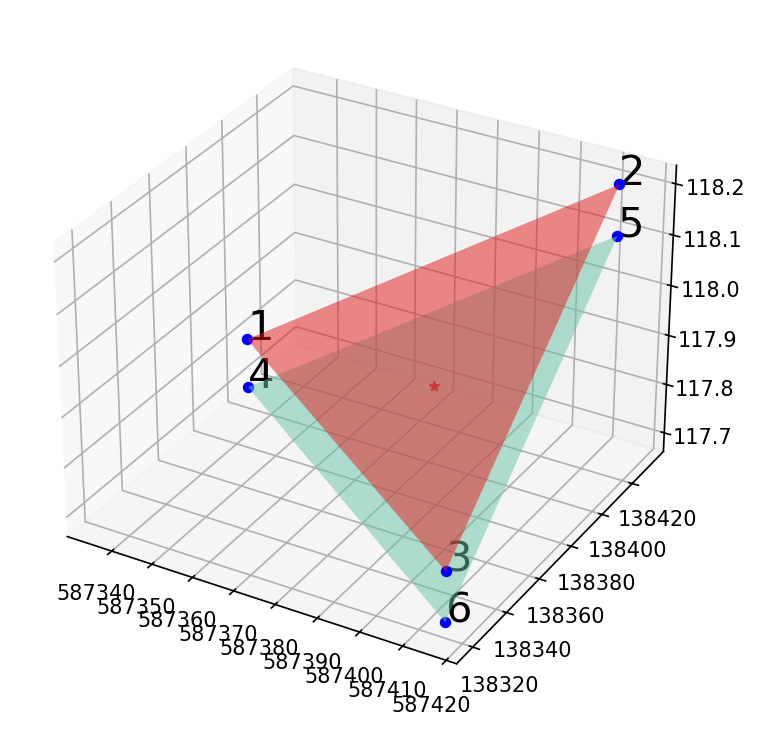

In [194]:
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
import numpy as np
from matplotlib import cm

fig = plt.figure(figsize=(8,6))
ax = fig.add_subplot(111, projection='3d')

for i in np.arange(6):
    ax.scatter(ivert_coord[i, 0], ivert_coord[i, 1], ivert_coord[i, 2],
               c='b', marker='o')
    ax.text(ivert_coord[i, 0], ivert_coord[i, 1], ivert_coord[i, 2], 
            '%s' % str(i + 1), size=20, zorder=1, color='k') 
    
# Scatter the mean point
ax.scatter(ivert_coord[:, 0].mean(), ivert_coord[:, 1].mean(), 
           ivert_coord[:, 2].mean(), c='r', marker='*')

# Plot trisurf on the first three points
ax.plot_trisurf(ivert_coord[:3, 0], ivert_coord[:3, 1], ivert_coord[:3, 2], 
                cmap=cm.Set1, linewidth=1, alpha=0.5)

# Plot trisurf on the remaining three points
ax.plot_trisurf(ivert_coord[3:, 0], ivert_coord[3:, 1], ivert_coord[3:, 2], 
                cmap=cm.Set2, linewidth=1, alpha=0.5)

# Display the plot
plt.show()



## get centroid for all cells

In [22]:
centr = []
for i in np.arange(cell_vert.shape[0])[:]:

    ivert_id = cell_vert[i, 1:]
    # vertice id is 1-based
    ivert_coord = vert_coord[ivert_id-1, :]  
    
    icentr = ivert_coord[:, 0].mean(), ivert_coord[:, 1].mean(), ivert_coord[:, 2].mean()
    centr.append(icentr)

centr = np.asarray(centr)

In [23]:
with open("/global/homes/z/zc727/HFR/mesh/{}-centroid-layerID.p".format(name), 'wb') as f:
    pickle.dump(centr, f, protocol=-1)

### sample dem elevation for each cell

In [24]:
with open("/global/homes/z/zc727/HFR/mesh/{}-centroid-layerID.p".format(name), 'rb') as f:
    centr = pickle.load(f)

In [25]:
centr_xy = centr[:, 0:2]

In [ ]:
# centr_xy_unq = np.vstack({tuple(row) for row in centr_xy})

Sample point value at each cell center

In [26]:
centr_df = pd.DataFrame(centr, columns= ['x', 'y', 'z'])

This will take a long time... Make sure to save the `centr_df` for reuse!

In [27]:
with rasterio.open(fname_dem) as ras:
    ele_dem = [i[0] for i in ras.sample(centr_xy[:])]

with rasterio.open(fname_coldcreek_basal) as ras:
    ele_cc = [i[0] for i in ras.sample(centr_xy[:])]
with rasterio.open(fname_taylorflats_basal) as ras:
    ele_tf = [i[0] for i in ras.sample(centr_xy[:])]
with rasterio.open(fname_ringolde_basal) as ras:
    ele_re = [i[0] for i in ras.sample(centr_xy[:])]    
with rasterio.open(fname_ringoldlm_basal) as ras:
    ele_rlm = [i[0] for i in ras.sample(centr_xy[:])]
with rasterio.open(fname_ringolda_basal) as ras:
    ele_ra = [i[0] for i in ras.sample(centr_xy[:])]
with rasterio.open(fname_basalt_basal) as ras:
    ele_ba = [i[0] for i in ras.sample(centr_xy[:])]

In [28]:
centr_df['dem'] = ele_dem
centr_df['cc'] = ele_cc
centr_df['tf'] = ele_tf
centr_df['re'] = ele_re
centr_df['rlm'] = ele_rlm
centr_df['ra'] = ele_ra
centr_df['ba'] = ele_ba

In [29]:
centr_df['layer_ids'] = layer_ids

In [30]:
with open("/global/homes/z/zc727/HFR/mesh/{}-centroid_df.p".format(name), 'wb') as f:
    pickle.dump(centr_df, f, protocol=-1)

### assign material id

**assign material id based on its relative elevation to cell coords**

material|id
---|---
hf|1
cold creek|2
taylor flats|3
ringolde|4
ringoldlm|5
ringolda|6
basalt|9
alluvium|10


Note, the stratigraphy follows the order Hanford >-- ColdCreek > taylor flats > ringolde > ringold lm > ringold a > basalt

In [31]:
with open("/global/homes/z/zc727/HFR/mesh/{}-centroid_df.p".format(name), 'rb') as f:
    centr_df = pickle.load(f)

In [207]:
# mat_ids = [1 if centr_df.loc[i, "z"] > centr_df.loc[i, "hr_elev"] 
#  else 4 for i in np.arange(centr_df.shape[0]) ]

In [32]:
material_list = {'dem':1, 'cc':2, 'tf':3, 're':4, 'rlm':5, 'ra':6, 'ba':9}

In [33]:
mat_ids = []
for i in tqdm(np.arange(centr_df.shape[0])[:]):
    row =centr_df.iloc[i, :]
    lst = row.z - row.iloc[3:-1] 

    if all(lst > 0): 
        # if z above all layers, assign hf=1
        mat = 1
    elif not any(lst >0): 
        # if z below all layers, assign ba=9
        mat = 9
    else:
        # if z in between layers, assign material id of the layer immediately above z
        mat = material_list[lst[lst <0].index[-1]]    
    mat_ids.append(mat)

  0%|          | 0/902937 [00:00<?, ?it/s]

In [34]:
centr_df['mat_ids'] = mat_ids

In [35]:
with open("/global/homes/z/zc727/HFR/mesh/{}-matID.p".format(name), 'wb') as f:
    pickle.dump(centr_df, f, protocol=-1)

**assign alluvium layer**

In [36]:
with open("/global/homes/z/zc727/HFR/mesh/{}-matID.p".format(name), 'rb') as f:
    centr_df = pickle.load(f)

In [12]:
river_shp = shapefile.Reader(fname_river_shp) 
river_shp = river_shp.shapes() 
# river_poly = [shape.points for shape in river_shp]
river_poly = river_shp[0].points

In [38]:
river_idx = [Polygon(river_poly).contains(Point(centr_df.loc[i, 'x'], centr_df.loc[i, 'y'])) 
             for i in centr_df.index]

In [39]:
centr_df['river_idx'] = river_idx

In [40]:
# Assume alluvium layer thickess = 1.0 m (thickness of top five layers: 0.1, 0.15, 0.22, 0.34, 0.51 m)
centr_df.loc[(centr_df['layer_ids'] <= 5) & 
             (centr_df['river_idx'] == True), 'mat_ids'] = 10

**plot material ids**

<Axes: xlabel='x', ylabel='y'>

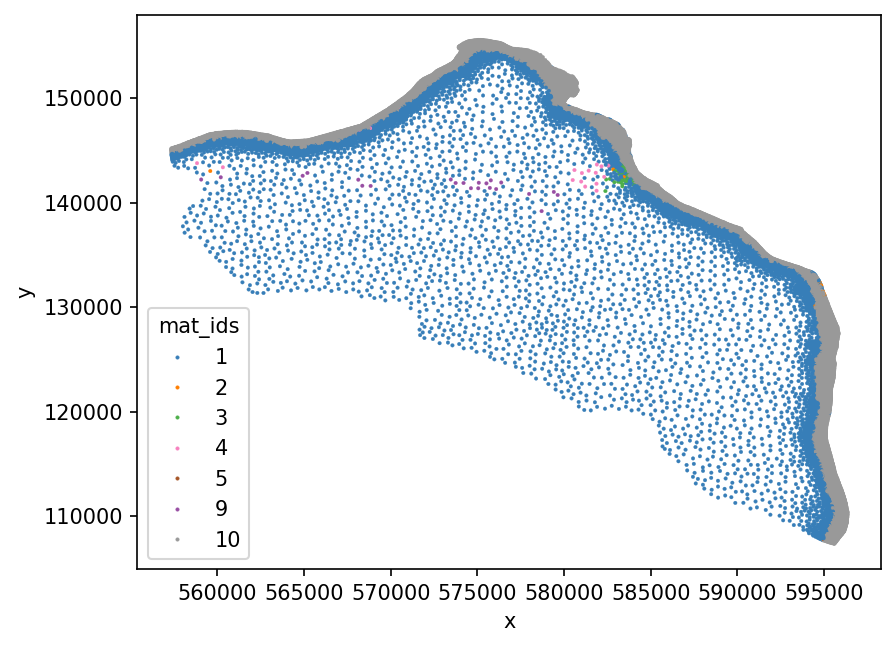

In [41]:
def colors(name):
    if name == 'CB_color_cycle':
        return ["#377eb8", "#ff7f00", "#4daf4a", "#f781bf", "#a65628", "#984ea3", "#999999", "#e41a1c", "#dede00"]
    return sns.color_palette(name)

ilayer = centr_df[centr_df['layer_ids'] == 1]

sns.scatterplot(x = 'x', y = 'y', hue = 'mat_ids', 
                marker = 'o', s=3,
                palette=sns.color_palette(colors('CB_color_cycle'), len(ilayer.mat_ids.unique())),
                edgecolor=None,
               data=ilayer, )

In [71]:
print(centr_df.mat_ids.unique())

[ 1 10  3  2  4  5  9  6]


/global/homes/p/pshuai/.conda/envs/exodus/lib/python3.8/site-packages/IPython/core/pylabtools.py:132: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


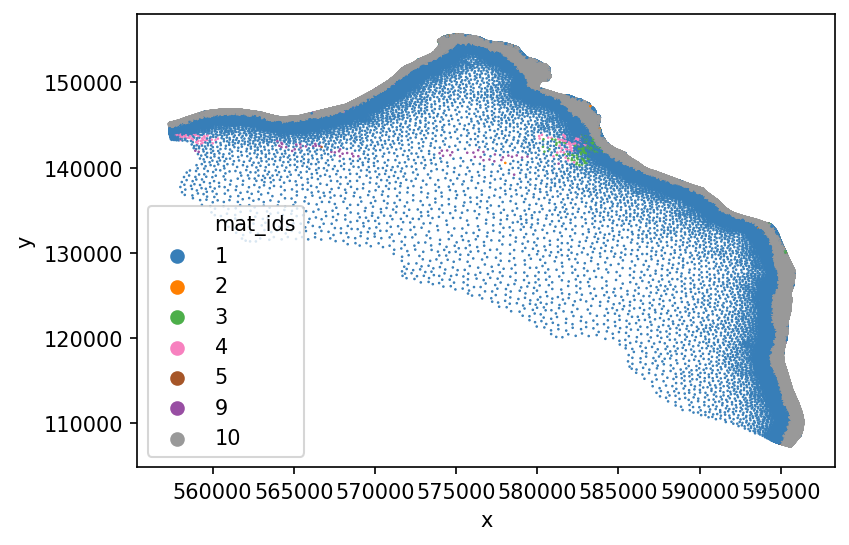

In [56]:
# old 100-m model, coarse vertical resolution 0.5 m, 0.5 m, 2 m, ..., 
# more gradual increase in horizontal resolution away from the river

In [42]:
with open("/global/homes/z/zc727/HFR/mesh/{}-matID_alluvium.p".format(name), 'wb') as f:
    pickle.dump(centr_df, f, protocol=-1)

**assign material ids based on layer id (optional)**

- Layer #1 is located on top and follow the sequence 1, 2, 3, ...; 

- Without knowing its layerID, select the cells based on their relative location in the cell index. i.e., `1 : ele_per_layer` belongs to layer 1.

In [116]:
# # layers = [101, 102] # top 2 layers
# # add alluvium id --5 to the two top layers while the cell id is Hf -- 1
# centr_df.loc[(centr_df['layer_ids'] <= 102) & (centr_df['mat_ids'] == 1), 'mat_ids'] = 5

In [61]:
# with open("../results/centr_df-coarse_matID.p", 'wb') as f:
#     pickle.dump(centr_df, f, protocol=-1)

In [43]:
input_h5.close()

### write material id to hdf5 file

In [44]:
with open("/global/homes/z/zc727/HFR/mesh/{}-matID_alluvium.p".format(name), 'rb') as f:
    centr_df = pickle.load(f)

In [45]:
in_h5 = h5.File(fname_out_h5, "r")

out_h5 = h5.File(fname_mesh_matID, 'w')

In [46]:
groups = list(in_h5.keys())
for i_group in groups:
    print(i_group)
    group_id = out_h5.require_group(i_group)
    datasets = list(in_h5[i_group].keys())
    for i_dataset in datasets:
        print(i_dataset)
        in_h5.copy("/" + i_group + "/" + i_dataset,
                      group_id, name=i_dataset)

Domain
Cells
Vertices
Materials
Cell Ids
Layer Ids
Material Ids
Regions
All
Bottom
Sides
Top


**read in material ids**

In [47]:
data = out_h5['Materials/Material Ids']       # load the data
data[...] = centr_df['mat_ids'].values

In [48]:
np.allclose(np.array(data), centr_df.mat_ids) # check if the new mat_ids has been read in.
#print(type(np.array(data)))

True

In [67]:
# del out_h5['Materials/Layer Ids']

In [49]:
in_h5.close()
out_h5.close()

## locate cells （optional)

In [50]:
with open("/global/homes/z/zc727/HFR/mesh/{}-matID_alluvium.p".format(name), 'rb') as f:
    centr_df = pickle.load(f)

In [51]:
icell = 25300
centr_df.loc[icell, :]
#print(type(centr_df))

x            557358.660737
y            144981.861854
z                116.68786
dem               112.3395
cc               82.592941
tf               82.592941
re               82.592941
rlm              79.126587
ra               41.085911
ba               41.085911
layer_ids                1
mat_ids                 10
river_idx             True
Name: 25300, dtype: object

# Add river region

Currently, the meshes generated from watershed workflow has some problems in geting the top face correct. See **3.2** for steps. 

In [5]:
with open("/global/homes/z/zc727/HFR/mesh/{}-matID_alluvium.p".format(name), 'rb') as f:
    centr_df = pickle.load(f)

In [6]:
in_h5 = h5.File(fname_mesh_matID, "r")

out_h5 = h5.File(fname_mesh_matID_river, 'w')

In [7]:
vert_coord = np.array(in_h5['Domain/Vertices'][:])

cell_vert = np.array(in_h5['Domain/Cells'][:])

In [8]:
groups = list(in_h5.keys())
for i_group in groups:
    print(i_group)
    group_id = out_h5.require_group(i_group)
    datasets = list(in_h5[i_group].keys())
    for i_dataset in datasets:
        print(i_dataset)
        in_h5.copy("/" + i_group + "/" + i_dataset,
                      group_id, name=i_dataset)

Domain
Cells
Vertices
Materials
Cell Ids
Layer Ids
Material Ids
Regions
All
Bottom
Sides
Top


In [9]:
mass1_df = pd.read_csv(fname_mass1_coord)

mass1_coord = mass1_df[['easting', 'northing']]

## get river cells from top sidesets (watershed_workflow)

Do this if you are not sure about the internal ordering of each vertex. Works for meshes from Watershed Workflow.

In [10]:
def get_cell_center(vertex_id):
    
    ivert_coord = vert_coord[vertex_id - 1, :]  
    icentr = ivert_coord[:, 0].mean(), ivert_coord[:, 1].mean(), ivert_coord[:, 2].mean()
    
    return icentr

In [13]:
top_vertex = np.array(in_h5['Regions/Top/Vertex Ids'][:])
top_cell_center = [get_cell_center(i) for i in top_vertex[:, 1:4]]

river_idx = [Polygon(river_poly).contains(Point(top_cell_center[i][0], top_cell_center[i][1])) 
             for i in np.arange(len(top_cell_center))]

top_river_cells = top_vertex[river_idx]
top_river_cell_coord = np.array(top_cell_center)[river_idx]

In [14]:
mass1_list = []

for i in tqdm(np.arange(len(top_river_cells))):
    iriver_cell = (top_river_cell_coord[i, 0], top_river_cell_coord[i, 1])
    idx = closest_node(iriver_cell, mass1_coord)
    imass = mass1_df.loc[idx, 'quadrant']
    mass1_list.append(imass)

mass1_list_unique = sorted(np.unique(mass1_list))

  0%|          | 0/19476 [00:00<?, ?it/s]

In [15]:
print(np.shape(mass1_coord))
print(np.shape(iriver_cell))
print(i)

(360, 2)
(2,)
19475


In [16]:
river_cells_df = centr_df[(centr_df['river_idx'] == True) & (centr_df['layer_ids'] ==1)].copy()

In [17]:
print(river_cells_df.columns)

Index(['x', 'y', 'z', 'dem', 'cc', 'tf', 're', 'rlm', 'ra', 'ba', 'layer_ids',
       'mat_ids', 'river_idx'],
      dtype='object')


In [18]:
river_cells_df['mass1_id']= mass1_list

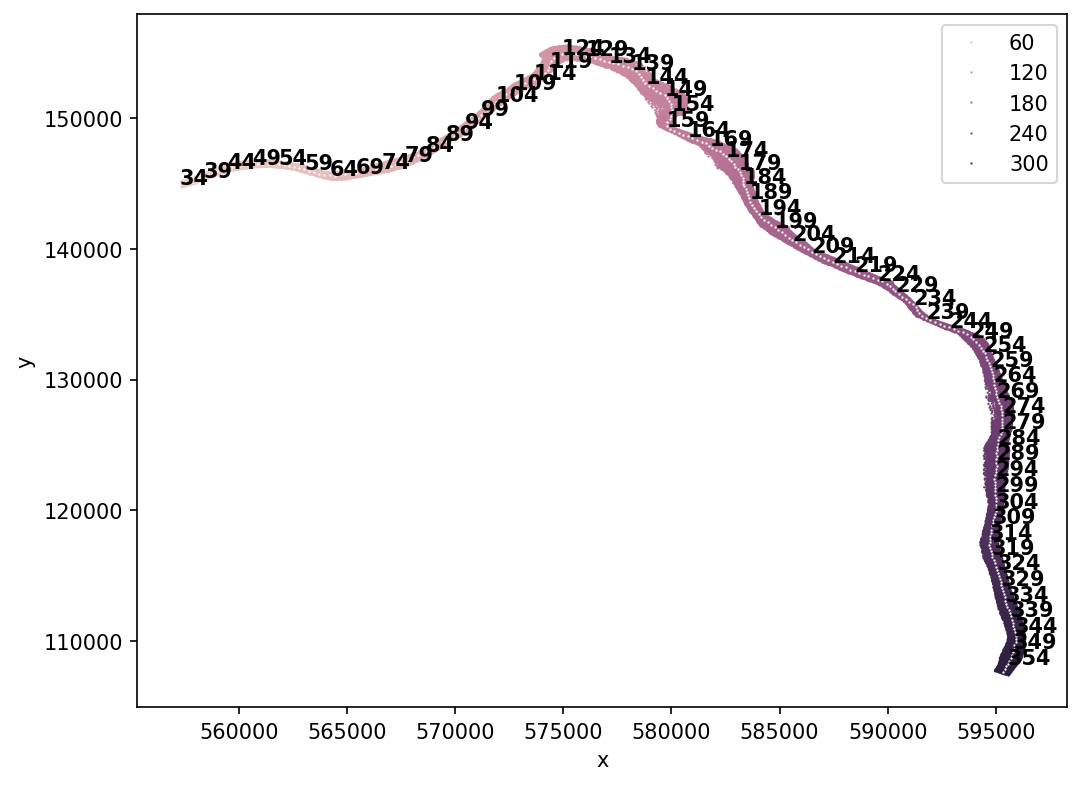

In [63]:
plt.figure(figsize=(8, 6))
p1=sns.scatterplot(data= river_cells_df,x='x', y='y', hue='mass1_id',  s= 1, edgecolor = None)
p2=sns.scatterplot(data = mass1_coord.loc[river_cells_df.mass1_id.unique()-1, :],x='easting', y='northing', color = 'white', s = 1)

for i in mass1_coord.loc[river_cells_df.mass1_id.unique()-1, :].sort_index().index[::5]:
    p2.text(mass1_coord.loc[i, 'easting'], mass1_coord.loc[i, 'northing'], mass1_coord.loc[i].name, 
           horizontalalignment='left', 
     size='medium', color='black', weight='semibold')

In [19]:
for imass in tqdm(mass1_list_unique):
#     imass = 250 # 1-based
    imass_name = 'Mass1_' + str(imass)
    # find river cells within the mass1
    icells = [i for i, e in enumerate(mass1_list) if e == imass]
    ivertex_ids = top_river_cells[icells]
    
#     for i in ivertex_ids:
#     if i.tolist() not in top_vertex.tolist():
#         raise Exception('cell face vertex_id {} not found in top surface vertex_ids for region {}'.format(i, imass_name))
    # write to hdf5 file
    out_h5.create_group("Regions/" + imass_name)
    out_h5.create_dataset("Regions/" + imass_name + "/Vertex Ids", data= ivertex_ids)

  0%|          | 0/325 [00:00<?, ?it/s]

## get river cells based on layer id (Tinerator)

Only do this if you are certain about the ordering of vertex in each cell. This works for meshes generated using TINERATOR.

In [66]:
# river_cells_df = centr_df[(centr_df['river_idx'] == True) & (centr_df['layer_ids'] ==1)].copy()

In [72]:
# mass1_list = []

# for i in tqdm(river_cells_df.index):
#     iriver_cell = (river_cells_df.loc[i, 'x'], river_cells_df.loc[i, 'y'])
#     idx = closest_node(iriver_cell, mass1_coord)
#     imass = mass1_df.loc[idx, 'quadrant']
#     mass1_list.append(imass)

# mass1_list_unique = sorted(np.unique(mass1_list))

In [17]:
# with open('../pickle/mass1_list.txt', 'w') as f:
#     for item in mass1_list_unique:
#         f.write("%s\n" % item)

In [73]:
# river_cells_df['mass1_id']= mass1_list

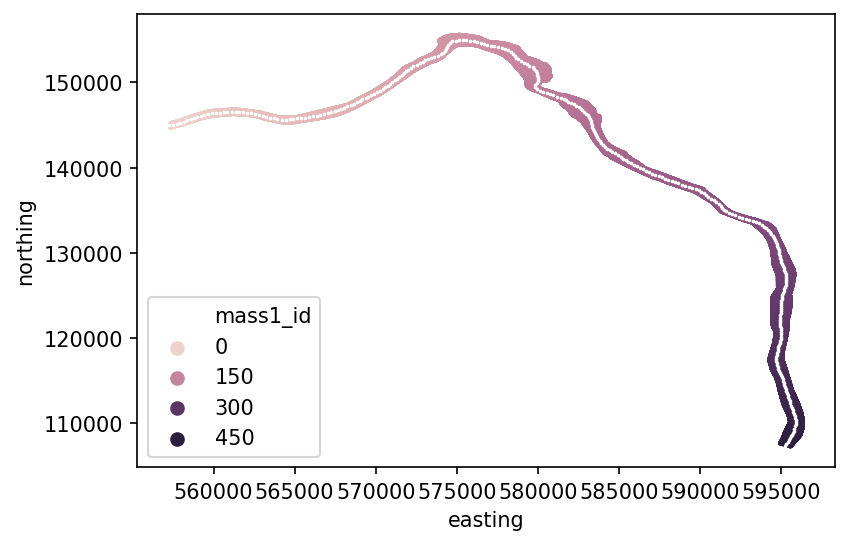

In [75]:
# sns.scatterplot('x', 'y', 'mass1_id', data= river_cells_df, 
#                 s= 1, edgecolor = None)
# sns.scatterplot('easting', 'northing', color = 'white', s = 1,
#                 data = mass1_coord.loc[river_cells_df.mass1_id.unique()-1, :])

In [79]:
# mass1_unique = sorted(river_cells_df.mass1_id.unique())

In [ ]:
# for imass in tqdm(mass1_list_unique):
# #     imass = 250 # 1-based
#     imass_name = 'Mass1_' + str(imass)
#     # find river cells within the mass1
#     icells = river_cells_df[river_cells_df['mass1_id'] == imass].index

#     # find all vertices for the river cells
# #     ivert_id = cell_vert[icells, 1:]

#     # get top cell face vertex ids, vertices ordered from bottom to top?
#     # choose the last three vertices for meshes generated by TINERATOR
# #     iface_vert = cell_vert[icells, 4:]   
#     # the face vertex id order is not known in watershed workflow!
#     iface_vert = cell_vert[icells, 1:4] 

#     ivertex_ids = np.concatenate((np.tile(3, (iface_vert.shape[0], 1)), 
#                                   iface_vert, 
#                                   np.tile(0, (iface_vert.shape[0], 1))), axis = 1)

# #     if not all([i in top_vertex for i in ivertex_ids]):
#     for i in ivertex_ids:
#         if i.tolist() not in top_vertex.tolist():
#             raise Exception('cell face vertex_id {} not found in top surface vertex_ids for region {}'.format(i, imass_name))
# #         break
# #     # get unique vertices
# #     iunique_vert = np.array(list(set(x for l in ivert_id for x in l)))

# #     # get vertice coordinates, vertice id is 1-based
# #     ivert_coord = vert_coord[iunique_vert -1, :] 

    
    
#     # write to hdf5 file
#     out_h5.create_group("Regions/" + imass_name)
#     out_h5.create_dataset("Regions/" + imass_name + "/Vertex Ids", data= ivertex_ids)

## save to hdf5

In [20]:
out_h5.visititems(print_structure)

Domain
Domain/Cells
Domain/Vertices
Materials
Materials/Cell Ids
Materials/Layer Ids
Materials/Material Ids
Regions
Regions/All
Regions/All/Cell Ids
Regions/Bottom
Regions/Bottom/Vertex Ids
Regions/Mass1_100
Regions/Mass1_100/Vertex Ids
Regions/Mass1_101
Regions/Mass1_101/Vertex Ids
Regions/Mass1_102
Regions/Mass1_102/Vertex Ids
Regions/Mass1_103
Regions/Mass1_103/Vertex Ids
Regions/Mass1_104
Regions/Mass1_104/Vertex Ids
Regions/Mass1_105
Regions/Mass1_105/Vertex Ids
Regions/Mass1_106
Regions/Mass1_106/Vertex Ids
Regions/Mass1_107
Regions/Mass1_107/Vertex Ids
Regions/Mass1_108
Regions/Mass1_108/Vertex Ids
Regions/Mass1_109
Regions/Mass1_109/Vertex Ids
Regions/Mass1_110
Regions/Mass1_110/Vertex Ids
Regions/Mass1_111
Regions/Mass1_111/Vertex Ids
Regions/Mass1_112
Regions/Mass1_112/Vertex Ids
Regions/Mass1_113
Regions/Mass1_113/Vertex Ids
Regions/Mass1_114
Regions/Mass1_114/Vertex Ids
Regions/Mass1_115
Regions/Mass1_115/Vertex Ids
Regions/Mass1_116
Regions/Mass1_116/Vertex Ids
Regions/Mas

In [21]:
in_h5.close()
out_h5.close()